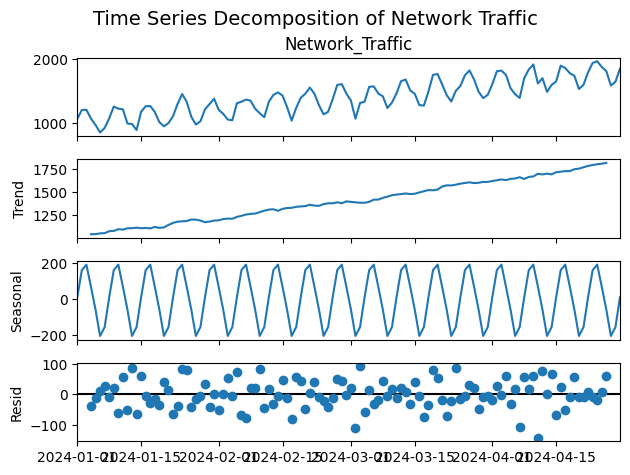

In [2]:
# Experiment 1: Perform a Time Series Decomposition of a Dataset with Seasonal and Trend Components.
# Import pandas for data manipulation
import pandas as pd

# Import numpy for numerical calculations
import numpy as np

# Import matplotlib for plotting graphs
import matplotlib.pyplot as plt

# Import seasonal decomposition function
from statsmodels.tsa.seasonal import seasonal_decompose

# Create 120 daily dates starting from 1st January 2024
dates = pd.date_range(start="2024-01-01", periods=120, freq="D")

# Generate an increasing trend from 1000 to 1800
trend = np.linspace(1000, 1800, 120)

# Create weekly seasonal variations using a sine wave
seasonal = 200 * np.sin(np.arange(120) * 2 * np.pi / 7)

# Generate random noise to make the data realistic
noise = np.random.normal(0, 50, 120)

# Combine trend, seasonality, and noise to create network traffic data
traffic = trend + seasonal + noise

# Create a DataFrame containing dates and network traffic
data = pd.DataFrame({
    "Date": dates,
    "Network_Traffic": traffic
})

# Set the Date column as the index for time series analysis
data.set_index("Date", inplace=True)

# Perform additive time series decomposition with weekly seasonality
result = seasonal_decompose(data["Network_Traffic"], model="additive", period=7)

# Plot the original, trend, seasonal, and residual components
result.plot()

# Add a title to the decomposition plot
plt.suptitle("Time Series Decomposition of Network Traffic", fontsize=14)
plt.subplots_adjust(top=0.88)   # Creates space between title and plots

# Display the graph
plt.show()

In [2]:
pip install statsmodels

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 358.9 kB/s eta 0:00:26
   -- ------------------------------------- 0.5/9.5 MB 358.9 kB/s eta 0:00:26
   --- ------------------------------------ 0.8/9.5 MB 425.3 kB/s eta 0:00:21
   --- ------------------------------------ 0.8/9.5 MB 425.3 kB/s eta 0:00:21
   --- ------------------------------------ 0.8/9.5 MB 425.3 kB/s eta 0:00:21
   ---- ----------------------------------- 1.0/9.5 MB 430.1 kB/s eta 0:00:20
   ---- ----------------------------------- 1.0/9


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


First Five Records
                     Flow_Count
Timestamp                      
2024-01-01 00:00:00  103.973713
2024-01-01 00:01:00   98.913906
2024-01-01 00:02:00  105.221548
2024-01-01 00:03:00  112.244299
2024-01-01 00:04:00   98.206853


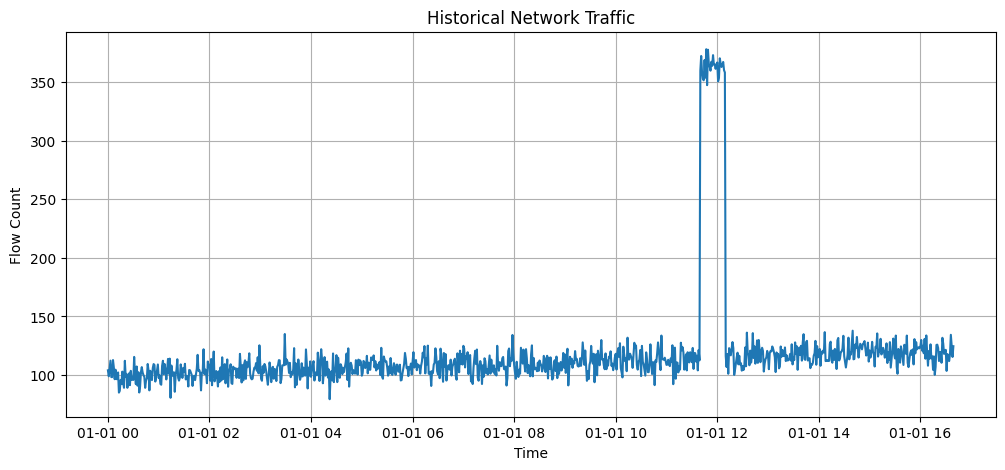


ARIMA Model Summary

                               SARIMAX Results                                
Dep. Variable:             Flow_Count   No. Observations:                  950
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -3935.811
Date:                Fri, 07 Aug 2026   AIC                           7881.622
Time:                        07:24:56   BIC                           7905.899
Sample:                    01-01-2024   HQIC                          7890.872
                         - 01-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -1.0191      0.190     -5.364      0.000      -1.392      -0.647
ar.L2         -0.1375      0.196     -0.700      0.484      -0.523       0.248
ma.L1          0.7782      0.1

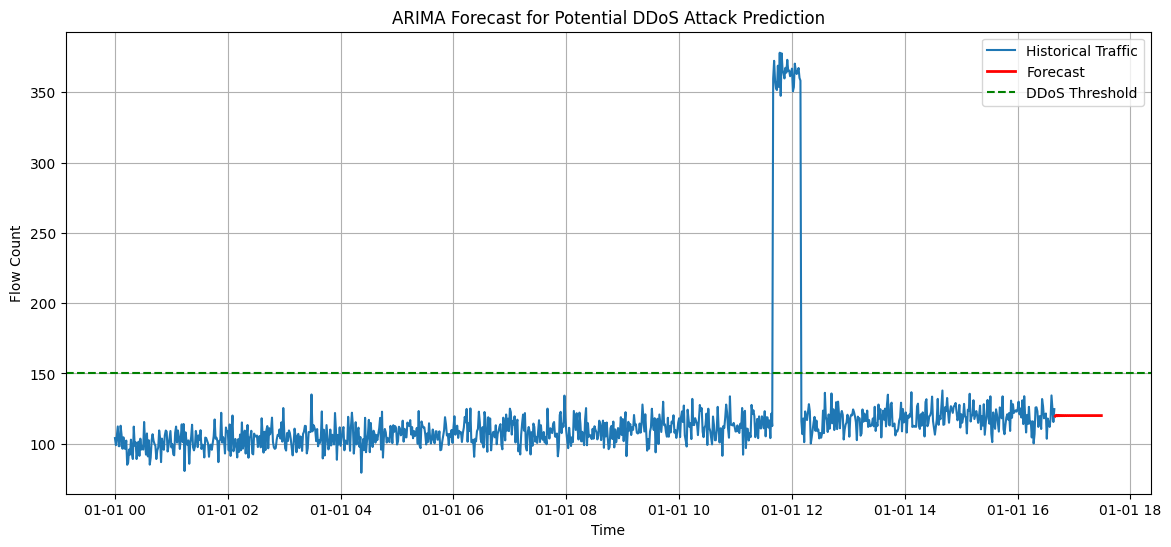


Potential DDoS Attack Predictions

No DDoS attack predicted in the forecast period.


In [3]:
# Experiment 2:  Using historical network traffic data, apply time series forecasting methods (like ARIMA or Prophet) to predict potential DDoS attacks

# Time Series Forecasting for Predicting Potential DDoS Attacks
# Using ARIMA Model
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
import warnings

# Ignore unnecessary warnings
warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# STEP 1 : Generate Historical Network Traffic Data
# ------------------------------------------------------------

# Make results reproducible
np.random.seed(42)

# Create timestamps (1000 minutes)
timestamps = pd.date_range(
    start="2024-01-01 00:00:00",
    periods=1000,
    freq="min"
)

# Generate normal network traffic
traffic = np.random.normal(
    loc=100,      # average flow count
    scale=8,      # variation
    size=1000
)

# Add a small increasing trend
traffic = traffic + np.linspace(0, 20, 1000)

# ------------------------------------------------------------
# STEP 2 : Simulate a DDoS Attack
# ------------------------------------------------------------

# Create sudden traffic spikes
traffic[700:730] += 250

# Create DataFrame
df = pd.DataFrame({
    "Timestamp": timestamps,
    "Flow_Count": traffic
})

# Set timestamp as index
df.set_index("Timestamp", inplace=True)

print("First Five Records")
print(df.head())

# ------------------------------------------------------------
# STEP 3 : Plot Historical Traffic
# ------------------------------------------------------------

plt.figure(figsize=(12,5))
plt.plot(df["Flow_Count"])
plt.title("Historical Network Traffic")
plt.xlabel("Time")
plt.ylabel("Flow Count")
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# STEP 4 : Split Dataset
# ------------------------------------------------------------

train = df["Flow_Count"][:-50]

# ------------------------------------------------------------
# STEP 5 : Build ARIMA Model
# ------------------------------------------------------------

model = ARIMA(train, order=(2,1,2))

model_fit = model.fit()

print("\nARIMA Model Summary\n")
print(model_fit.summary())

# ------------------------------------------------------------
# STEP 6 : Forecast Future Traffic
# ------------------------------------------------------------

forecast = model_fit.forecast(steps=50)

future_time = pd.date_range(
    start=df.index[-1] + pd.Timedelta(minutes=1),
    periods=50,
    freq="min"
)

forecast_df = pd.DataFrame({
    "Timestamp": future_time,
    "Predicted_Flow_Count": forecast
})

forecast_df.set_index("Timestamp", inplace=True)

print("\nFuture Predictions\n")
print(forecast_df)

# ------------------------------------------------------------
# STEP 7 : Detect Potential DDoS Attack
# ------------------------------------------------------------

# Threshold
threshold = 150

forecast_df["Prediction"] = np.where(
    forecast_df["Predicted_Flow_Count"] > threshold,
    "Potential DDoS Attack",
    "Normal Traffic"
)

print("\nPrediction Result\n")
print(forecast_df)

# ------------------------------------------------------------
# STEP 8 : Plot Forecast
# ------------------------------------------------------------

plt.figure(figsize=(14,6))

# Historical Traffic
plt.plot(
    df.index,
    df["Flow_Count"],
    label="Historical Traffic"
)

# Forecast
plt.plot(
    forecast_df.index,
    forecast_df["Predicted_Flow_Count"],
    color="red",
    linewidth=2,
    label="Forecast"
)

# Threshold Line
plt.axhline(
    y=threshold,
    color="green",
    linestyle="--",
    label="DDoS Threshold"
)

plt.title("ARIMA Forecast for Potential DDoS Attack Prediction")
plt.xlabel("Time")
plt.ylabel("Flow Count")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# STEP 9 : Display Only Potential DDoS Predictions
# ------------------------------------------------------------

attacks = forecast_df[
    forecast_df["Prediction"] == "Potential DDoS Attack"
]

print("\nPotential DDoS Attack Predictions\n")

if len(attacks) == 0:
    print("No DDoS attack predicted in the forecast period.")
else:
    print(attacks)

# ------------------------------------------------------------
# END OF PROGRAM
# ------------------------------------------------------------